In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("/content/Customer Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [7]:
df["TotalCharges"]=df["TotalCharges"].replace(" ",0)

In [8]:
df["TotalCharges"]=df["TotalCharges"].astype("float")

In [9]:
#customer id should be unique so we check that is there any dupilcates out there

In [10]:
df["customerID"].duplicated().sum()

np.int64(0)

In [12]:
"""And in senerior citizen column it is like 0 and 1 i wqould like to
no and yes for it"""


'And in senerior citizen column it is like 0 and 1 i wqould like to\nno and yes for it'

In [13]:
def conv(Value):
  if Value==1:
    return "Yes"
  else:
    return"No"
df["SeniorCitizen_label"]=df["SeniorCitizen"].apply(conv)

In [14]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,SeniorCitizen_label
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,No
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,No


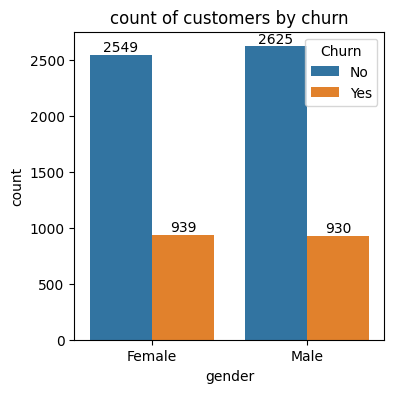

In [15]:
plt.figure(figsize=(4,4))
ax=sns.countplot(x="gender",data=df,hue="Churn");
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])

plt.title("count of customers by churn");
plt.show()

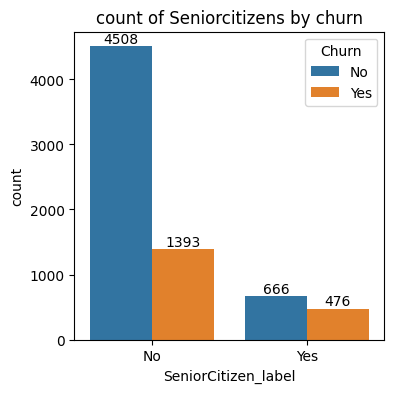

In [16]:
plt.figure(figsize=(4,4))
ax=sns.countplot(x="SeniorCitizen_label",data=df,hue="Churn");
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("count of Seniorcitizens by churn");
plt.show()


In [17]:
pd.crosstab(df["SeniorCitizen"], df["Churn"])

Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


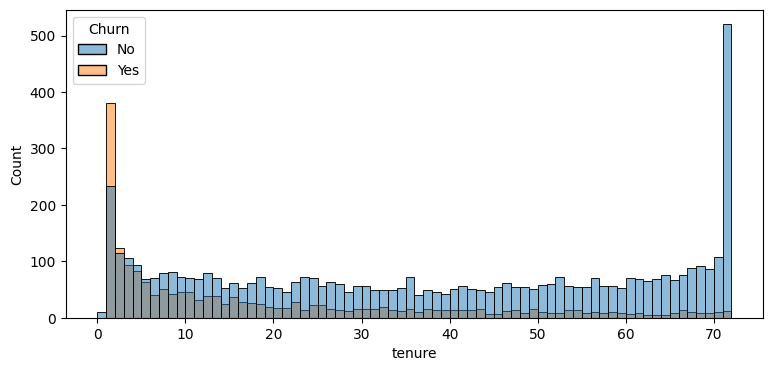

In [21]:
plt.figure(figsize=(9,4))
sns.histplot(x="tenure",data=df,bins=72,hue="Churn")
plt.show()

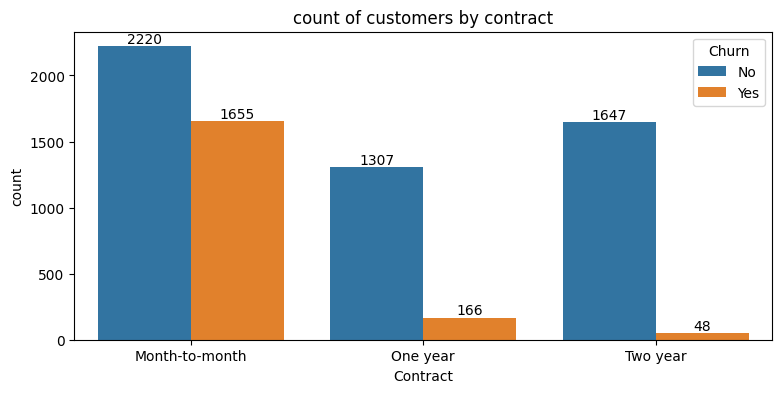

In [23]:
plt.figure(figsize=(9,4))
ax=sns.countplot(x="Contract",data=df,hue="Churn");
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("count of customers by contract");
plt.show()

In [24]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'SeniorCitizen_label'],
      dtype='object')

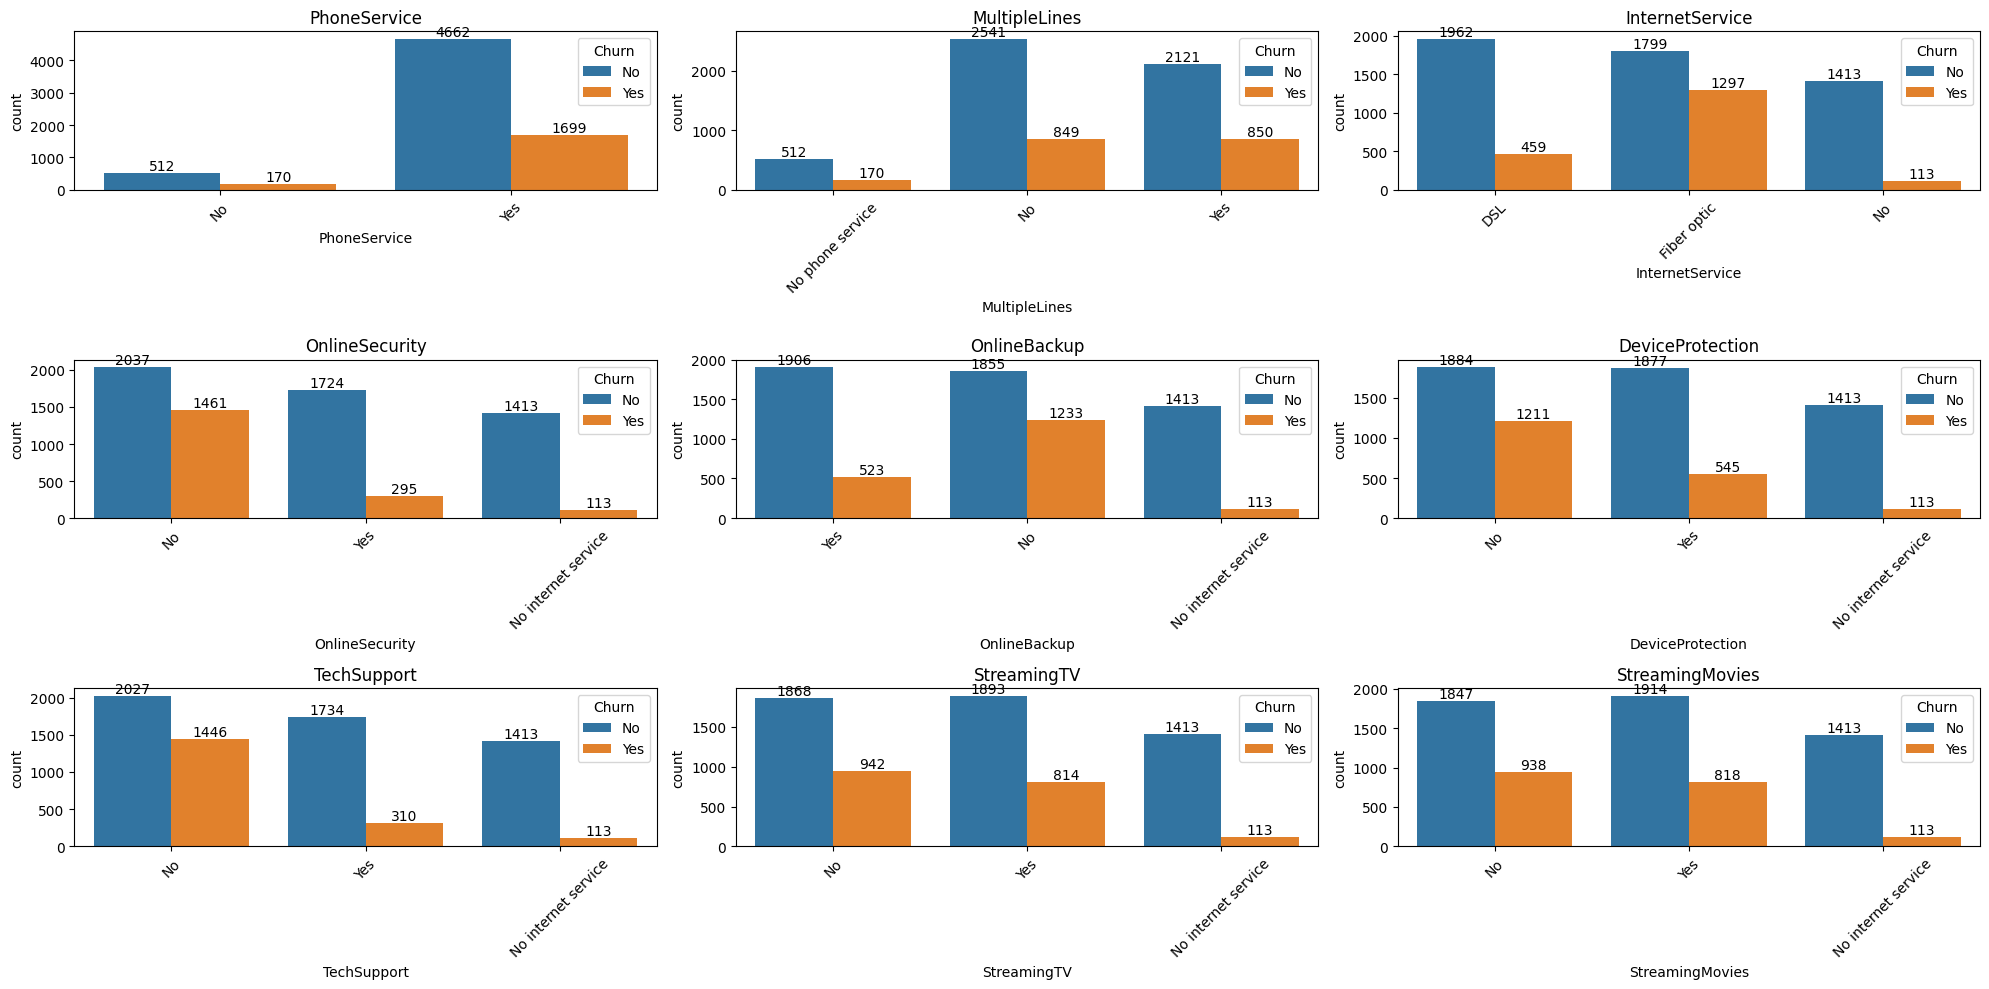

In [25]:

cols = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

plt.figure(figsize=(20,10))

for i, col in enumerate(cols, 1):
    ax = plt.subplot(3, 3, i)
    sns.countplot(x=col, data=df, hue="Churn", ax=ax)

    # add data labels
    for container in ax.containers:
        ax.bar_label(container)

    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

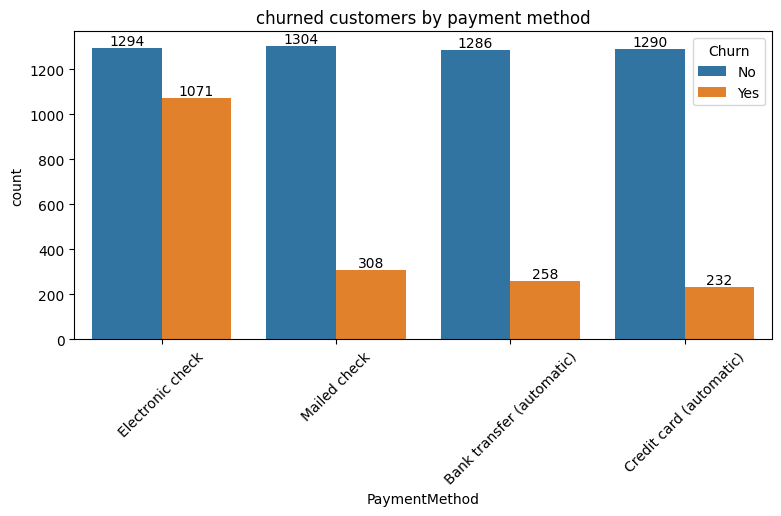

In [28]:
plt.figure(figsize=(9,4))
ax=sns.countplot(x="PaymentMethod",data=df,hue="Churn");
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("churned customers by payment method");
plt.xticks(rotation=45)
plt.show()

In [29]:
"""observations:
1.41% of senior citizens are churned out
 formula==churned/total senior citen*100
2.people whao have taken shorter duration tenure(1-10) months have churned lesser compared to who have taken longer duration
3.people  who take month_month contract get more churned hen compared to other
4.people who have phone service are churning a little bit more compared to people who don't have a phone service
5.people who have optic fiber internet service service are churning out more
6.people who don't have online security are churning out way more
7.people who don't have online backup are churning out way more
8.people who don't have Device protection are churning out way more
9.people who don't have tech support are churning out way more
10..people who have streaming tv  are churning a little bit more compared to others
11.people who have opted for the automaic payment method are churning less when compared to people who opted for electronic check and
and mail check.peole who are opting electronic check are churning ot more """

"observations:\n1.41% of senior citizens are churned out \n formula==churned/total senior citen*100\n2.people whao have taken shorter duration tenure(1-10) months have churned lesser compared to who have taken longer duration\n3.people  who take month_month contract get more churned hen compared to other\n4.people who have phone service are churning a little bit more compared to people who don't have a phone service\n5.people who have optic fiber internet service service are churning out more\n6.people who don't have online security are churning out way more\n7.people who don't have online backup are churning out way more\n8.people who don't have Device protection are churning out way more\n9.people who don't have tech support are churning out way more\n10..people who have streaming tv  are churning a little bit more compared to others\n11.people who have opted for the automaic payment method are churning less when compared to people who opted for electronic check and \nand mail check.

In [ ]:
"""📊 Customer Churn Analysis Project
🎯 Project Objective

The objective of this project is to analyze customer churn behavior and identify the key factors influencing customers to leave the service, so that the company can design effective retention strategies and reduce churn rate, thereby improving customer satisfaction and long-term revenue.

🔍 Key Observations

Senior Citizens Churn Rate

About 41% of senior citizens have churned.

This indicates that senior customers are a high-risk segment and may face usability, pricing, or service issues.

Tenure vs Churn

Customers with shorter tenure (1–10 months) show lower churn compared to customers with longer tenure.

This suggests that churn increases as customers spend more time with the service, possibly due to dissatisfaction over time.

Contract Type

Customers with month-to-month contracts churn significantly more than those with one-year or two-year contracts.

Longer contracts help in customer retention.

Phone Service

Customers who have phone service churn slightly more compared to those without phone service.

This may indicate pricing or service quality issues related to phone services.

Internet Service Type

Customers using fiber optic internet show a higher churn rate.

This could be due to higher costs, service reliability issues, or customer expectations not being met.

Online Security

Customers without online security churn at a much higher rate.

Security services clearly play an important role in customer retention.

Online Backup

Customers who do not have online backup are churning significantly more.

Backup services add value and increase customer stickiness.

Device Protection

Customers without device protection exhibit a higher churn rate.

This suggests customers value device safety and support services.

Tech Support

Lack of technical support strongly correlates with higher churn.

Customers need reliable assistance when facing technical issues.

Streaming TV

Customers who have streaming TV services churn slightly more compared to others.

This may indicate pricing concerns or content satisfaction issues.

Payment Method

Customers using automatic payment methods churn less.

Customers using electronic check churn the most, followed by mailed checks.

Automatic payments increase customer retention and commitment.

💡 Recommendations to Reduce Churn
1️⃣ Focus on Senior Citizens

Provide senior-friendly plans

Offer simpler interfaces, dedicated support, and discounted bundles

Introduce priority customer support for seniors

2️⃣ Improve Long-Term Customer Experience

Monitor customer satisfaction over time

Provide loyalty rewards after certain tenure milestones (12, 24 months)

Conduct regular feedback surveys for long-tenure customers

3️⃣ Encourage Long-Term Contracts

Offer discounts or benefits for switching from month-to-month to yearly plans

Provide contract upgrade incentives

4️⃣ Improve Fiber Optic Service Quality

Investigate network reliability and pricing

Improve service performance and customer communication

Offer service guarantees or compensation for outages

5️⃣ Bundle Value-Added Services

Encourage customers to opt for:

Online Security

Online Backup

Device Protection

Tech Support

📌 These services significantly reduce churn and increase customer dependency.

6️⃣ Improve Payment Experience

Promote automatic payment methods using:

Discounts

Cashback offers

Convenience messaging

Reduce friction in electronic check payment process

7️⃣ Re-evaluate Streaming Services

Analyze pricing vs content satisfaction

Offer custom streaming bundles

Provide trial or flexible streaming plans

✅ Final Conclusion

Customer churn is strongly influenced by contract type, service quality, security features, and payment methods.
By focusing on high-risk customer segments, improving service reliability, and promoting long-term engagement, the company can significantly reduce churn and improve customer retention."""